---
title: "ASM1: a stoichiometric matrix that checks itself"
description: "The activated sludge model is eight processes and thirteen components arranged in a Petersen matrix. Read it off the 1987 page and the continuity relations that the component definitions force close exactly: charge and nitrogen identically, COD everywhere except two cells, where the residual is exactly the rounding of 20/7 to 2.86 and 32/7 to 4.57."
categories: [sec:J, struct:S1, tier:T1, data:tier2, phase:liquid]
date: 2026-07-30
---

# ASM1: a stoichiometric matrix that checks itself

**Catalog ID:** `J4.8` · **Structures:** `S1` (reaction network), `S4` · **Tier:** T1

The IAWPRC Activated Sludge Model No. 1 is the most widely used model in
environmental engineering, and it is not a set of differential equations. It is
**one table**: eight biological processes down the side, thirteen components
across the top, and a stoichiometric coefficient in each box.

That table has a property most published kinetic schemes do not: it is
**self-checking**. The components are declared in units of COD, of nitrogen, and
of ionic charge, and those declarations force three conservation relations on
every row. Reproducing the matrix and then testing whether continuity closes is a
much stronger validation than fitting any curve: it either holds as an exact
identity or it does not, and there is no tolerance to negotiate.

It closes. And where it does not, the discrepancy turns out to be exactly the
two-decimal rounding of two conversion factors printed in the table.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.19"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "J4.8-asm1-activated-sludge"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. Packages beyond pymrm and the Colab defaults (numpy, scipy, pandas,
# matplotlib, pyyaml) are installed here with subprocess, not %pip.
import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from pymrm.checks import find_roots, observed_orders
from gallery_utils import load_data, load_meta, cite_data, Claims
import model as asm      # the page's model.py, put on sys.path by setup()

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])

## Background

A single-sludge plant does three jobs at once. Heterotrophs oxidise organic
carbon, using oxygen where it is available and nitrate where it is not.
Autotrophs oxidise ammonia to nitrate, but only aerobically. And the sludge
itself decays, releasing substrate and nitrogen back into the liquid. The
processes compete for the same electron acceptors in the same tank, which is why
the task group set out to find the simplest model still capable of realistic
predictions for single-sludge systems.

What they produced is presented in the **matrix format of Petersen (1965)**:
components across the top, processes down the side, and a rate expression on the
right. The observed conversion rate of any component is then one column sum,

$$ r_i = \sum_j \nu_{ij}\,\rho_j $$

which is the paper's equation (1). This is not a presentational convenience. The
matrix layout makes the stoichiometry inspectable in a way that a list of ODEs
never is, and it makes the conservation checks below possible at all.

**Why the units matter more than they look.** The paper insists on three
conventions and then says why:

- every organic component is in **COD**, so "calculation of the oxygen
  requirement by a simple COD balance" becomes possible;
- every nitrogen species is expressed **as N**, so the two conversion factors
  2.86 and 4.57 are needed "to convert nitrate nitrogen and ammonia nitrogen
  concentrations, respectively, to an equivalent COD basis";
- alkalinity is in **molar units**, included so that "undue changes in pH can be
  predicted and avoided"; the paper's threshold is 50 g m⁻³ as CaCO₃, below
  which "the pH becomes unstable and can fall to values well below 6".

Those three conventions are exactly what makes the matrix testable. Each one
defines a linear functional on the component vector, and each such functional
must annihilate every row of the matrix.

## The published model

**Thirteen components.** Seven in COD units ($S_I$, $S_S$, $X_I$, $X_S$,
$X_{B,H}$, $X_{B,A}$, $X_P$), oxygen as *negative* COD ($S_O$), four nitrogen
species ($S_{NO}$, $S_{NH}$, $S_{ND}$, $X_{ND}$), and alkalinity ($S_{ALK}$).

**Eight processes.** Aerobic and anoxic growth of heterotrophs; aerobic growth of
autotrophs; decay of each biomass; ammonification; and hydrolysis of entrapped
organics and of entrapped organic nitrogen.

The whole of Table 1, every stoichiometric coefficient and every rate
expression, is transcribed into `data/` and loaded below rather than retyped
into the notebook. **Nothing came from the PDF text layer**, which scrambles the
matrix completely: it renders $1/Y_H$ as `I / r~`, $(4.57-Y_A)/Y_A$ as
`4 . 5 7 - Y4 / Y,~`, and drops most of the alkalinity column. Both journal
pages were rendered at 600 dpi and read as images.

**The three continuity relations.** These are *not* printed in the paper: this
is the abbreviated report, and it states the conventions but never writes the
balances out. They follow from the component definitions alone. Assign each
component its content of a conserved quantity and require

$$ \sum_i \gamma_i \,\nu_{ij} = 0 \qquad\text{for every process } j $$

for $\gamma$ = theoretical oxygen demand, nitrogen, and ionic charge.

| $\gamma$ | how the paper fixes it |
|---|---|
| **COD** | $+1$ for the seven organic components (declared in COD units), $-1$ for $S_O$ ("oxygen, negative COD"), $0$ for $S_{NH}$, $S_{ND}$, $X_{ND}$ and $S_{ALK}$ |
| **N** | $1$ for the four nitrogen species (all "given as nitrogen"), $i_{XB}$ for both biomasses and $i_{XP}$ for $X_P$ (the paper's own definitions of those two parameters) |
| **charge** | $+1/14$ for $S_{NH}$ (NH₄⁺, per g N), $-1/14$ for $S_{NO}$ (NO₃⁻), $-1$ for $S_{ALK}$ (alkalinity in molar units) |

Only $\gamma_\text{COD}(S_{NO})$ takes any thought, and the paper hands it over
too. Fix the reference oxidation state of nitrogen at $-\mathrm{III}$, ammonium
and organic amine, because that is what dichromate COD measures. Then, per gram
of N,

$$\gamma_\text{COD}(S_{NH}) = 0,\qquad
  \gamma_\text{COD}(S_{N_2}) = -\tfrac{24}{14} = -\tfrac{12}{7},\qquad
  \gamma_\text{COD}(S_{NO}) = -\tfrac{64}{14} = -\tfrac{32}{7}. $$

**The paper's own two conversion factors are two differences on that one scale:**

$$ \underbrace{\tfrac{32}{7} - \tfrac{12}{7} = \tfrac{20}{7} = 2.857\ldots}_{\text{nitrate}\to\text{N}_2,\ \text{the printed }2.86}
\qquad
\underbrace{\tfrac{32}{7} - 0 = \tfrac{32}{7} = 4.571\ldots}_{\text{ammonium}\to\text{nitrate},\ \text{the printed }4.57} $$

That is the whole reason a single COD continuity can cover both denitrification
and nitrification, and it is the point on which everything below turns.

## Parameters and assumptions

**The continuity check needs no parameters at all.** It is an identity in the
five stoichiometric symbols $Y_H$, $Y_A$, $f_P$, $i_{XB}$, $i_{XP}$, and it is
verified symbolically below, not at a sample point. Table 4's numbers are needed
only for the illustrative reactor.

**Dinitrogen is not a component of ASM1, and it has to be.** The model tracks
$S_{NO}$ but the nitrogen leaving as N₂ gas goes nowhere, so nitrogen continuity
cannot possibly close on process 2 as printed. This page therefore carries a
fourteenth component $S_{N_2}$ with $\nu_{2,N_2} = -\nu_{2,NO}$, which is the
only addition made to the published matrix anywhere on this page. It affects
nothing else (no rate expression reads it), and later models (ASM2, ASM3) add
it for exactly this reason.

**A defect in Table 4, reported rather than repaired.** The paper says the model
"contains 13 components and 19 parameters", and Table 1's own parameter lists
name exactly nineteen. **Table 4 prints one row more** (counted from the CSV
below). The extra one is a second ammonification coefficient: $k_a = 0.016$
m³(g cell COD·day)⁻¹ sits in the right place in the kinetic block, and
$k_A = 0.08$ m³ COD (g·day)⁻¹ is appended after $b_A$, under a symbol that is
defined nowhere in the model. Both rows were re-read at 8× magnification to
confirm the subscript case. This page does not pick one by inference: the
reactor is run at both, and the difference is reported.

**Parameter choice for the reactor, and why it is not cherry-picked.** Table 4
gives ranges, several of them very wide (the widest is printed below). Every
parameter is the **geometric mean** of its printed range, applied uniformly: the
scale-invariant centre for a rate constant, and a rule with no freedom left in
it. The value it returns for $b_H$ is essentially the one the later ASM1
literature settled on.

**Assumptions inherited from the paper** (its own list, §"Assumptions and
restrictions"): constant temperature; constant, near-neutral pH; organic matter
of constant nature; no nutrient limitation other than nitrogen; fixed
denitrification correction factors; nitrification coefficients unaffected by
other constituents; homogeneous heterotrophic biomass; instantaneous entrapment
of particulate organic matter; hydrolysis of organic matter and organic nitrogen
coupled at equal rates; and decay independent of electron acceptor.

**The operating point of the lane is ours, not the paper's**: the paper contains
no worked example. An average municipal wastewater blended 1:1 with return
sludge, an 8 h lane residence time on that blended flow, internal recycle twice
the blended flow, and oxygen held at 2 g m⁻³ in the aerated section.

In [3]:
# The lane's operating point (ours; the paper gives no example)
TAU_LANE = 8.0 / 24.0     # lane volume / (influent + return sludge flow), d
R_INT = 2.0               # internal mixed-liquor recycle ratio, -
SO_SET = 2.0              # dissolved-oxygen setpoint in the aerated section, g m-3
KLA = 2000.0              # d-1, large enough that the setpoint is held; OTR is the output
F_ANOX = 0.30             # unaerated fraction of the lane at the base case, -
BLEND = 0.5               # wastewater fraction of the blend entering the lane (1:1), -
ALK_LIMIT = 50.0          # the paper's pH-stability threshold, g CaCO3 m-3
CACO3 = 50.0              # g CaCO3 per mol of alkalinity (equivalent mass)

# raw wastewater and return sludge, g m-3 (alkalinity mol m-3)
WW = dict(S_I=30., S_S=70., X_I=50., X_S=200., X_BH=0., X_BA=0., X_P=0.,
          S_O=0., S_NO=0., S_NH=30., S_ND=5., X_ND=10., S_ALK=6., S_N2=0.)
RAS = dict(S_I=30., S_S=3., X_I=1500., X_S=120., X_BH=3000., X_BA=160., X_P=1400.,
           S_O=0., S_NO=8., S_NH=1., S_ND=1., X_ND=12., S_ALK=4., S_N2=18.)
print(f"one pass through the lane takes {24 * TAU_LANE / (1 + R_INT):.2f} h "
      f"(residence time over 1 + R)")

one pass through the lane takes 2.67 h (residence time over 1 + R)


## The data

Four transcribed tables, each with a provenance sidecar. This is a **tier 2**
page in the gallery's source hierarchy (printed tables, no digitising, no
figure extraction), which is exactly right for a paper whose entire content is a
table.

| file | what it holds |
|---|---|
| `henze-1987-table1-components.csv` | the component symbols, names and units |
| `henze-1987-table1-stoichiometry.csv` | the Petersen matrix, as algebraic expressions |
| `henze-1987-table1-rates.csv` | the process rate expressions |
| `henze-1987-table4-parameters.csv` | typical values at 20 °C, both ammonification rows |

There is **no experimental data on this page and there should not be**. The
source is an abbreviated report; its only figure with measurements in it (Fig. 1,
an oxygen-uptake trace) is reproduced *from* Ekama et al. (1986) to illustrate a
measurement procedure, not to test the model. Presenting a re-simulation as data
would be circular, so the page's weight is carried by the continuity checks
instead, which is the stronger test anyway, because they admit no free
parameter.

In [4]:
comp = load_data("henze-1987-table1-components.csv", page=PAGE)
stoi = load_data("henze-1987-table1-stoichiometry.csv", page=PAGE, dtype=str)
rates = load_data("henze-1987-table1-rates.csv", page=PAGE)
pars = load_data("henze-1987-table4-parameters.csv", page=PAGE)

C13 = list(comp.symbol)                   # the paper's components, in order
COMPS = C13 + ["S_N2"]                    # + dissolved dinitrogen, see above
IX = {c: k for k, c in enumerate(COMPS)}
NC = len(COMPS)
Y_H, Y_A, f_P, i_XB, i_XP = (asm.SYMS[s] for s in asm.STOICH_SYMBOLS)
SYMS = dict(asm.SYMS)

NU = asm.petersen_matrix(stoi, C13)
n_nonblank = sum(v != 0 for row in NU.values() for v in row.values())
print(f"{len(NU)} processes x {len(C13)} components + S_N2 "
      f"({n_nonblank} non-blank cells, {n_nonblank - 1} of them printed)")
print(f"Table 4 prints {len(pars)} parameter rows")
print(cite_data(load_meta("henze-1987-table1-stoichiometry.csv", page=PAGE)))

# parameters: geometric mean of every printed range, no exceptions
P = {r.symbol: float(np.sqrt(r.value_min * r.value_max)) for r in pars.itertuples()}
P["k_a"] = float(pars.loc[pars.symbol == "k_a", "value_min"].iloc[0])  # the model's own symbol
K_A_ALT = float(pars.loc[pars.symbol == "k_A", "value_min"].iloc[0])  # the undefined extra row
widest = max(pars.itertuples(), key=lambda r: r.value_max / r.value_min)
print(f"widest printed range: {widest.symbol} from {widest.value_min:g} to "
      f"{widest.value_max:g}, a factor of {widest.value_max / widest.value_min:.0f}")
print("\nparameters used for the reactor (geometric mean of each Table 4 range):")
for k in ("Y_H", "Y_A", "f_P", "i_XB", "i_XP", "mu_hat_H", "K_S", "K_OH", "K_NO",
          "b_H", "eta_g", "eta_h", "k_a", "k_h", "K_X", "mu_hat_A", "K_NH", "K_OA", "b_A"):
    print(f"   {k:9s} {P[k]:9.4g}")

8 processes x 13 components + S_N2 (31 non-blank cells, 30 of them printed)
Table 4 prints 20 parameter rows
Henze, M.; Grady, C. P. L. Jr; Gujer, W.; Marais, G. v. R.; Matsuo, T. (1987) — Water Research 21(5) 505-515 — doi:10.1016/0043-1354(87)90058-3 — table
widest printed range: b_H from 0.09 to 4.38, a factor of 49

parameters used for the reactor (geometric mean of each Table 4 range):
   Y_H          0.5634
   Y_A            0.14
   f_P            0.08
   i_XB          0.086
   i_XP           0.06
   mu_hat_H      6.293
   K_S           42.43
   K_OH        0.03873
   K_NO         0.1414
   b_H          0.6279
   eta_g        0.7746
   eta_h           0.4
   k_a           0.016
   k_h             2.2
   K_X            0.15
   mu_hat_A     0.4701
   K_NH           1.47
   K_OA              1
   b_A          0.0866


## PyMRM implementation

Three pieces, in order of how much they carry.

**1. The matrix and its composition vectors** (`model.py`). Held symbolically, so
continuity is an identity rather than a numerical coincidence. Nothing here
needs a solver.

**2. The eight rate expressions**, evaluated pointwise on an array of states.
These enter only the reactor demonstration; no check below depends on them.

**3. A plug-flow aeration lane.** The paper argues that its hydrolysis model
exists to produce "realistic space-time and real-time dependent electron acceptor
profiles", so a spatially resolved lane is the natural demonstration: a
pre-denitrification (Modified Ludzack-Ettinger) arrangement with an unaerated
head end and internal mixed-liquor recycle.

That is an `S1` reaction network riding on one-dimensional convection:

$$ \frac{\partial}{\partial z}\left(u\,c_i\right)
   = \sum_j \nu_{ij}\rho_j(c) + \delta_{i,S_O}\,k_La\,(S_O^{\ast}-S_O) $$

with `construct_convflux_upwind` + `construct_div` (`nu=0`, constant area) for
the transport and `NumJac((n, 14))` + `newton` for the steady state.
`NumJac` couples only the last axis, which is the correct stencil here because
the source is pointwise: the components in a cell interact with each other and
with nothing next door. The outlet is `{"outflow": True}`, so the exit face
carries the last cell's value, and a face sits exactly on the aeration
boundary so the anoxic/aerobic step never falls inside a cell.

**The inlet is not free.** The internal recycle takes mixed liquor from the lane
outlet back to the head, so $c_\text{in} = (c_\text{feed} + R\,c_\text{out})/(1+R)$.
The inlet condition is built with `shapes_d`, so the inlet value is an external
vector multiplying a constant matrix, and $c_\text{out}$ is the exit-face row of
the same convection operator. The recycle is then one more constant sparse
matrix in the Newton system: one solve, every operator assembled once. The
nitrate arriving at the anoxic zone is *predicted* by the nitrification
downstream, not assumed. **The rate expressions clip negative concentrations**,
so Newton is bounded below by zero, `bounds=(0, None)`.

**What is specified rather than predicted.** The mixed-liquor solids entering the
lane. In a real plant they are set by the sludge age, which is a plant-level
control loop outside a single lane; over one pass the biomass barely moves
(printed below).

In [5]:
gamma = asm.composition_vectors(COMPS)
STOICH = {k: P[k] for k in asm.STOICH_SYMBOLS}
NU_M = asm.numeric_matrix(NU, STOICH)


def feed(alk=1.0, nh=1.0, blend=BLEND):
    """Wastewater blended with return sludge; alk and nh scale the raw-water
    alkalinity and ammonia."""
    scale = {"S_ALK": alk, "S_NH": nh}
    return np.array([blend * WW[c] * scale.get(c, 1.0) + (1 - blend) * RAS[c]
                     for c in COMPS])


def lane(n=150, f_anox=F_ANOX, nu_m=None, p=None, c_feed=None, R=R_INT, tol=1e-11, **kw):
    """The steady lane at the page's operating point, recycle inside the Newton solve."""
    L = asm.Lane(NU_M if nu_m is None else nu_m, P if p is None else p, IX,
                 feed() if c_feed is None else c_feed, n=n, f_anox=f_anox, R=R,
                 tau=TAU_LANE, so_set=SO_SET, kla=KLA, **kw)
    return L.solve(tol=tol)


def tn(c_out):
    """Total inorganic nitrogen of an outlet, g N m-3."""
    return c_out[IX["S_NH"]] + c_out[IX["S_NO"]]


print("lane: 14 components x n cells, one Newton solve with the recycle inside it")

lane: 14 components x n cells, one Newton solve with the recycle inside it


## Results

First the matrix as transcribed, then the three continuity residuals, then the
lane.

In [6]:
print("THE PETERSEN MATRIX AS TRANSCRIBED (blank boxes omitted)\n")
for r in stoi.itertuples():
    j = int(r.j)
    cells_j = [(c, getattr(r, c)) for c in C13
               if not (isinstance(getattr(r, c), float) and np.isnan(getattr(r, c)))]
    print(f"  {j}  {r.process}")
    print("     " + "   ".join(f"{c} = {v}" for c, v in cells_j))
    print(f"     rho_{j} = {rates.rate[j - 1]}\n")

print(f"sparsity, {len(NU)} x {len(C13)} (X = printed coefficient, + = the added S_N2 cell):")
print("      " + " ".join(f"{c:>5s}" for c in COMPS))
for j in sorted(NU):
    marks = [("+" if c == "S_N2" else "X") if NU[j][c] != 0 else "." for c in COMPS]
    print(f"   {j}  " + " ".join(f"{m:>5s}" for m in marks))
n_cells = sum(NU[j][c] != 0 for j in NU for c in C13)
n_boxes = len(NU) * len(C13)
print(f"\n{n_cells} of the {n_boxes} boxes carry a coefficient; the other "
      f"{n_boxes - n_cells} are blank in the paper.")

THE PETERSEN MATRIX AS TRANSCRIBED (blank boxes omitted)

  1  Aerobic growth of heterotrophs
     S_S = -1/Y_H   X_BH = 1   S_O = -(1-Y_H)/Y_H   S_NH = -i_XB   S_ALK = -i_XB/14
     rho_1 = mu_hat_H*(S_S/(K_S+S_S))*(S_O/(K_OH+S_O))*X_BH

  2  Anoxic growth of heterotrophs
     S_S = -1/Y_H   X_BH = 1   S_NO = -(1-Y_H)/(2.86*Y_H)   S_NH = -i_XB   S_ALK = (1-Y_H)/(14*2.86*Y_H)-i_XB/14
     rho_2 = mu_hat_H*(S_S/(K_S+S_S))*(K_OH/(K_OH+S_O))*(S_NO/(K_NO+S_NO))*eta_g*X_BH

  3  Aerobic growth of autotrophs
     X_BA = 1   S_O = -(4.57-Y_A)/Y_A   S_NO = 1/Y_A   S_NH = -i_XB-1/Y_A   S_ALK = -i_XB/14-1/(7*Y_A)
     rho_3 = mu_hat_A*(S_NH/(K_NH+S_NH))*(S_O/(K_OA+S_O))*X_BA

  4  "Decay" of heterotrophs
     X_S = 1-f_P   X_BH = -1   X_P = f_P   X_ND = i_XB-f_P*i_XP
     rho_4 = b_H*X_BH

  5  "Decay" of autotrophs
     X_S = 1-f_P   X_BA = -1   X_P = f_P   X_ND = i_XB-f_P*i_XP
     rho_5 = b_A*X_BA

  6  Ammonification of soluble organic nitrogen
     S_NH = 1   S_ND = -1   S_ALK = 1/14
     r

In [7]:
def continuity_all(nu=None, g=None):
    """Residuals of the three laws on every process."""
    nu, g = NU if nu is None else nu, gamma if g is None else g
    return {law: asm.continuity(nu, g[law]) for law in ("COD", "N", "charge")}


res = continuity_all()
print("CONTINUITY OF THE PRINTED MATRIX, as symbolic identities\n")
print(f"{'j':>2} {'process':<44}{'COD':>26}{'N':>26}{'charge':>10}")
for j in sorted(NU):
    name = stoi.process[j - 1][:42]
    print(f"{j:>2} {name:<44}{sp.sstr(res['COD'][j]):>26}"
          f"{sp.sstr(res['N'][j]):>26}{sp.sstr(res['charge'][j]):>10}")
n_cod_closed = sum(res["COD"][j] == 0 for j in NU)


def n_loss_without_n2(nu=None):
    """Nitrogen left unaccounted on process 2 when the S_N2 cell is blank."""
    nu = asm.petersen_matrix(stoi, C13, add_n2=False) if nu is None else nu
    return -asm.continuity(nu, gamma["N"])[2]          # residual is minus the loss


def n_loss_range(yield_row="Y_H"):
    """The process-2 nitrogen loss over Table 4's printed range of one yield row."""
    row = pars[pars.symbol == yield_row].iloc[0]
    f = sp.lambdify(Y_H, n_loss_without_n2())
    return sorted([float(f(row.value_min)), float(f(row.value_max))])


loss_expr = n_loss_without_n2()
loss_lo, loss_hi = n_loss_range()
print(f"\n-> charge closes on all {len(NU)} processes, exactly, for ANY parameter values.")
print(f"-> nitrogen closes on all {len(NU)} as well, but ONLY because S_N2 was added;")
loss_form = (1 - Y_H) / (sp.Rational(286, 100) * Y_H)
print(f"   without it process 2 leaves {sp.sstr(loss_form)}"
      f"{' = (1 - Y_H)/(2.86 Y_H)' if sp.simplify(loss_expr - loss_form) == 0 else ' (MISMATCH)'}"
      " g N per g of biomass COD grown")
print(f"   anoxically unaccounted for: {loss_lo:.2f} to {loss_hi:.2f} over Table 4's Y_H range.")
print(f"-> COD closes on {n_cod_closed} of {len(NU)}. The two residuals depend on no")
print("   stoichiometric parameter except the yield they divide; see the validation below.")

CONTINUITY OF THE PRINTED MATRIX, as symbolic identities

 j process                                                            COD                         N    charge
 1 Aerobic growth of heterotrophs                                       0                         0         0
 2 Anoxic growth of heterotrophs                     (Y_H - 1)/(1001*Y_H)                         0         0
 3 Aerobic growth of autotrophs                              -1/(700*Y_A)                         0         0
 4 "Decay" of heterotrophs                                              0                         0         0
 5 "Decay" of autotrophs                                                0                         0         0
 6 Ammonification of soluble organic nitrogen                           0                         0         0
 7 "Hydrolysis" of entrapped organics                                   0                         0         0
 8 "Hydrolysis" of entrapped organic nitrogen                 


-> charge closes on all 8 processes, exactly, for ANY parameter values.
-> nitrogen closes on all 8 as well, but ONLY because S_N2 was added;
   without it process 2 leaves 50*(1 - Y_H)/(143*Y_H) = (1 - Y_H)/(2.86 Y_H) g N per g of biomass COD grown
   anoxically unaccounted for: 0.16 to 0.41 over Table 4's Y_H range.
-> COD closes on 6 of 8. The two residuals depend on no
   stoichiometric parameter except the yield they divide; see the validation below.


Newton with the recycle inside: converged
            feed  lane inlet lane outlet
S_I       30.000     30.0000     30.0000
S_S       36.500     14.2919      3.1879
X_I      775.000    775.0000    775.0000
X_S      160.000    130.9370    116.4055
X_BH    1500.000   1434.4654   1401.6981
X_BA      80.000     80.5398     80.8096
X_P      700.000    715.9390    723.9085
S_O        0.000      1.1042      1.6563
S_NO       4.000     10.2868     13.4303
S_NH      15.500      5.5687      0.6030
S_ND       3.000      3.5503      3.8255
X_ND      11.000     10.0825      9.6238
S_ALK      5.000      3.8416      3.2623
S_N2       9.000     17.6448     21.9672

oxygen transfer rate 652.3 g O2 per m3 of lane per day
heterotroph biomass over one pass: -2.3 %


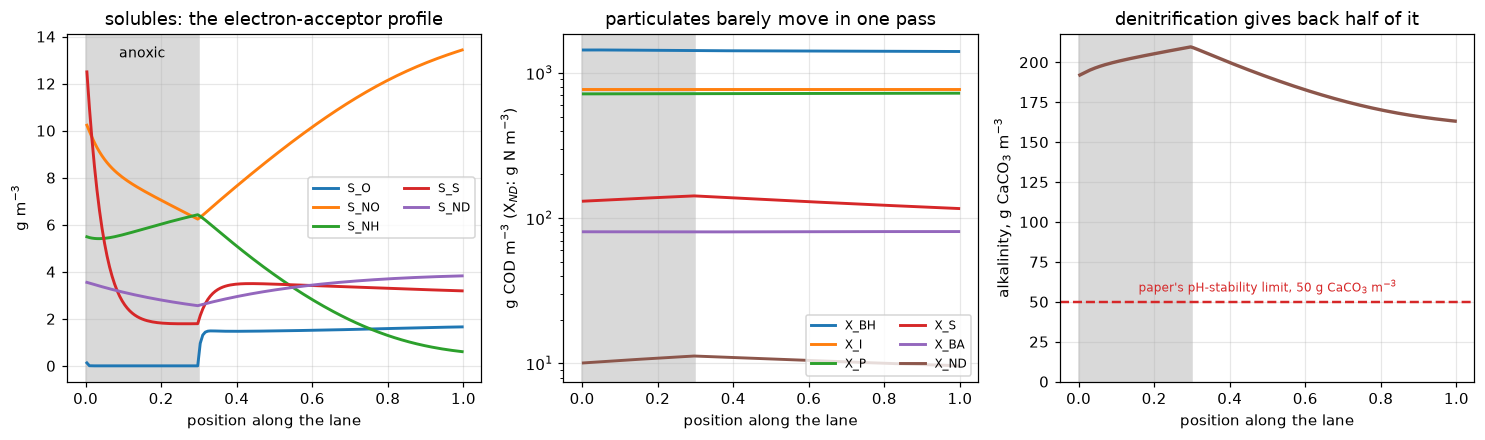

Denitrification consumes nitrate and releases oxygen demand in the unaerated
head end; nitrification rebuilds the nitrate and strips ammonia downstream.
Alkalinity rises through the anoxic zone and falls through the aerated one,
the behaviour the paper says column 13 was put in the model to predict.


In [8]:
S = lane()
c, c_in = S["c"], S["c_in"]
print("Newton with the recycle inside: converged")
print(f"{'':6s}{'feed':>10s}{'lane inlet':>12s}{'lane outlet':>12s}")
for k in COMPS:
    print(f"{k:6s}{S['feed'][IX[k]]:10.3f}{c_in[IX[k]]:12.4f}{S['c_out'][IX[k]]:12.4f}")
print(f"\noxygen transfer rate {S['otr']:.1f} g O2 per m3 of lane per day")
xbh_change = S["c_out"][IX["X_BH"]] / c_in[IX["X_BH"]] - 1
print(f"heterotroph biomass over one pass: {100 * xbh_change:+.1f} %")

fig, ax = plt.subplots(1, 3, figsize=(13.6, 4.1))
for k, col in (("S_O", "tab:blue"), ("S_NO", "tab:orange"), ("S_NH", "tab:green"),
               ("S_S", "tab:red"), ("S_ND", "tab:purple")):
    ax[0].plot(S["z"], c[:, IX[k]], lw=1.9, color=col, label=k)
ax[0].axvspan(0, F_ANOX, color="0.85", zorder=0)
ax[0].text(F_ANOX / 2, ax[0].get_ylim()[1] * 0.93, "anoxic", ha="center", fontsize=9)
ax[0].set(xlabel="position along the lane", ylabel="g m$^{-3}$",
          title="solubles: the electron-acceptor profile")
ax[0].legend(fontsize=8, ncol=2)

for k in ("X_BH", "X_I", "X_P", "X_S", "X_BA", "X_ND"):
    ax[1].plot(S["z"], c[:, IX[k]], lw=1.9, label=k)
ax[1].axvspan(0, F_ANOX, color="0.85", zorder=0)
ax[1].set(xlabel="position along the lane", ylabel="g COD m$^{-3}$ (X$_{ND}$: g N m$^{-3}$)",
          yscale="log", title="particulates barely move in one pass")
ax[1].legend(fontsize=8, ncol=2)

ax[2].plot(S["z"], c[:, IX["S_ALK"]] * CACO3, lw=2.2, color="tab:brown")
ax[2].axhline(ALK_LIMIT, color="tab:red", ls="--", lw=1.6)
ax[2].text(0.5, ALK_LIMIT + 6, "paper's pH-stability limit, 50 g CaCO$_3$ m$^{-3}$",
           fontsize=8, color="tab:red", ha="center")
ax[2].axvspan(0, F_ANOX, color="0.85", zorder=0)
ax[2].set(xlabel="position along the lane", ylabel="alkalinity, g CaCO$_3$ m$^{-3}$",
          ylim=(0, None), title="denitrification gives back half of it")
fig.tight_layout(); plt.show()

print("Denitrification consumes nitrate and releases oxygen demand in the unaerated")
print("head end; nitrification rebuilds the nitrate and strips ammonia downstream.")
print("Alkalinity rises through the anoxic zone and falls through the aerated one,")
print("the behaviour the paper says column 13 was put in the model to predict.")

## Validation

Six checks. The first three test the transcription without a solver anywhere
near them; the last three test the discretisation and the recycle solve.

In [9]:
print("1. THE TWO COD RESIDUALS ARE EXACTLY THE PRINTED ROUNDING\n")
d286 = sp.Rational(286, 100) - sp.Rational(20, 7)
d457 = sp.Rational(457, 100) - sp.Rational(32, 7)
print(f"   Printed:   2.86  vs  20/7 = {float(sp.Rational(20, 7))}")
print(f"              4.57  vs  32/7 = {float(sp.Rational(32, 7))}")
print(f"   Differences:  2.86 - 20/7 = {d286}      4.57 - 32/7 = {d457}\n")
print(f"   COD residual of process 2: {sp.sstr(res['COD'][2])}")
print(f"   COD residual of process 3: {sp.sstr(res['COD'][3])}\n")

NU_EXACT = asm.exact_factor_matrix(NU)
res_exact = continuity_all(NU_EXACT)
print("   Substituting 20/7 and 32/7 for the printed decimals:")
for law in ("COD", "N", "charge"):
    vals = [res_exact[law][j] for j in sorted(NU)]
    print(f"      {law:7s} residuals on all {len(NU)} processes: "
          f"{'all exactly zero' if all(v == 0 for v in vals) else vals}")
print("\n   So the printed matrix is continuous in COD, nitrogen and charge to the")
print(f"   last digit the typesetting allows, and the only defect in all {n_boxes} boxes")
print("   is that two repeating fractions were printed to two decimals.")

1. THE TWO COD RESIDUALS ARE EXACTLY THE PRINTED ROUNDING

   Printed:   2.86  vs  20/7 = 2.857142857142857
              4.57  vs  32/7 = 4.571428571428571
   Differences:  2.86 - 20/7 = 1/350      4.57 - 32/7 = -1/700

   COD residual of process 2: (Y_H - 1)/(1001*Y_H)
   COD residual of process 3: -1/(700*Y_A)

   Substituting 20/7 and 32/7 for the printed decimals:
      COD     residuals on all 8 processes: all exactly zero
      N       residuals on all 8 processes: all exactly zero
      charge  residuals on all 8 processes: all exactly zero

   So the printed matrix is continuous in COD, nitrogen and charge to the
   last digit the typesetting allows, and the only defect in all 104 boxes
   is that two repeating fractions were printed to two decimals.


In [10]:
print("2. PRINTED COEFFICIENTS RECOVERED FROM CONTINUITY ALONE\n")
print("   Delete a cell, solve the relevant balance for it, compare with the paper.")
print("   A single mis-read digit anywhere in the row would break this.\n")

TARGETS = [(1, "S_O", "COD"), (1, "S_ALK", "charge"),
           (2, "S_NO", "COD"), (2, "S_ALK", "charge"),
           (3, "S_O", "COD"), (3, "S_NH", "N"), (3, "S_ALK", "charge"),
           (4, "X_ND", "N"), (5, "X_ND", "N"), (6, "S_ALK", "charge")]


def recovery(nu=None, g=None):
    """Recover each target cell from its balance: (identical, rounding-only, rows)."""
    nu, g = NU if nu is None else nu, gamma if g is None else g
    rows = [(j, cell, law, asm.recover_cell(nu, g[law], j, cell)) for j, cell, law in TARGETS]
    n_same = sum(d == 0 for *_, d in rows)
    return n_same, len(rows) - n_same, rows


n_exact, n_rounding, rec_rows = recovery()
print(f"   {'j':>2} {'cell':<7}{'law':<8}{'as printed in Table 1':<34}"
      f"{'recovered minus printed':<26}verdict")
for j, cell, law, diff in rec_rows:
    verdict = "identical" if diff == 0 else "the 2.86 / 4.57 rounding"
    print(f"   {j:>2} {cell:<7}{law:<8}{stoi[cell][j - 1]:<34}"
          f"{sp.sstr(sp.nsimplify(diff)):<26}{verdict}")
print(f"\n   {n_exact} of {len(TARGETS)} come back symbolically identical to the printed cell.")
print(f"   The other {n_rounding} differ only by the rounding of check 1: the {d286} in 2.86")
print(f"   (process 2, S_NO) and the {-d457} in 4.57 (process 3, S_O).")

2. PRINTED COEFFICIENTS RECOVERED FROM CONTINUITY ALONE

   Delete a cell, solve the relevant balance for it, compare with the paper.
   A single mis-read digit anywhere in the row would break this.

    j cell   law     as printed in Table 1             recovered minus printed   verdict
    1 S_O    COD     -(1-Y_H)/Y_H                      0                         identical
    1 S_ALK  charge  -i_XB/14                          0                         identical
    2 S_NO   COD     -(1-Y_H)/(2.86*Y_H)               (Y_H - 1)/(2860*Y_H)      the 2.86 / 4.57 rounding
    2 S_ALK  charge  (1-Y_H)/(14*2.86*Y_H)-i_XB/14     0                         identical
    3 S_O    COD     -(4.57-Y_A)/Y_A                   -1/(700*Y_A)              the 2.86 / 4.57 rounding
    3 S_NH   N       -i_XB-1/Y_A                       0                         identical
    3 S_ALK  charge  -i_XB/14-1/(7*Y_A)                0                         identical
    4 X_ND   N       i_XB-f_P*i_XP          

In [11]:
print("3. THE PAPER'S OWN EQUATION (3) IS A FREE CROSS-CHECK\n")
print("   Equation (3) writes out r_2 = v21*rho_1 + v22*rho_2 + v27*rho_7 in full,")
print("   typeset separately from the matrix. Building it from the transcribed")
print("   matrix column and the transcribed rate rows must reproduce it exactly.\n")

syms = dict(SYMS)
syms.update({s: sp.Symbol(s) for s in
             ("S_S", "S_O", "S_NO", "S_NH", "S_ND", "X_S", "X_BH", "X_BA", "X_ND",
              "mu_hat_H", "mu_hat_A", "K_S", "K_OH", "K_NO", "K_NH", "K_OA",
              "b_H", "b_A", "k_a", "k_h", "K_X", "eta_g", "eta_h")})
RHO = {int(r.j): sp.sympify(r.rate, locals=syms) for r in rates.itertuples()}

# Equation (3) exactly as printed on journal page 507, read from the 600 dpi render
S_S_, S_O_, S_NO_, X_S_, X_BH_ = (syms[k] for k in ("S_S", "S_O", "S_NO", "X_S", "X_BH"))
K_S, K_OH, K_NO, K_X = (syms[k] for k in ("K_S", "K_OH", "K_NO", "K_X"))
mu_H, eta_g, eta_h, k_h = (syms[k] for k in ("mu_hat_H", "eta_g", "eta_h", "k_h"))
EQ3 = (-1 / Y_H * mu_H * (S_S_ / (K_S + S_S_)) * (S_O_ / (K_OH + S_O_)) * X_BH_
       - 1 / Y_H * mu_H * (S_S_ / (K_S + S_S_)) * (K_OH / (K_OH + S_O_))
       * (S_NO_ / (K_NO + S_NO_)) * eta_g * X_BH_
       + k_h * (X_S_ / X_BH_) / (K_X + (X_S_ / X_BH_))
       * ((S_O_ / (K_OH + S_O_)) + eta_h * (K_OH / (K_OH + S_O_)) * (S_NO_ / (K_NO + S_NO_)))
       * X_BH_)


def eq3_delta(nu=None):
    """Column S_S of the matrix times the rate column, minus equation (3)."""
    nu = NU if nu is None else nu
    return sp.simplify(sum(nu[j]["S_S"] * RHO[j] for j in (1, 2, 7)) - EQ3)


delta_eq3 = eq3_delta()
print("   column 2 of the matrix x the rate column, minus equation (3):", delta_eq3)
print("   ->", "identical" if delta_eq3 == 0 else "MISMATCH")
print("\n   That is three matrix cells and three rate rows confirmed against a part")
print("   of the paper set in a different place, at no cost.")

3. THE PAPER'S OWN EQUATION (3) IS A FREE CROSS-CHECK

   Equation (3) writes out r_2 = v21*rho_1 + v22*rho_2 + v27*rho_7 in full,
   typeset separately from the matrix. Building it from the transcribed
   matrix column and the transcribed rate rows must reproduce it exactly.

   column 2 of the matrix x the rate column, minus equation (3): 0
   -> identical

   That is three matrix cells and three rate rows confirmed against a part
   of the paper set in a different place, at no cost.


In [12]:
print("4. THE REACTOR CONSERVES WHAT THE MATRIX CONSERVES, AND LEAKS WHAT IT LEAKS\n")
print("   At steady state the flux of a conserved quantity through the lane can only")
print("   change by what crosses the boundary: here, the oxygen transferred in.")
print("   The fluxes come from the pymrm convection operator itself.\n")


def numeric_gamma(g=None):
    """Composition vectors as arrays at the reactor's stoichiometry."""
    g = gamma if g is None else g
    sub = {SYMS[k]: sp.Rational(str(P[k])) for k in asm.STOICH_SYMBOLS}
    return {law: np.array([float(g[law][c].subs(sub)) for c in COMPS]) for law in g}


G_NUM = numeric_gamma()
NU_M_EXACT = asm.numeric_matrix(NU_EXACT, STOICH)
GRIDS = (75, 150, 300)


def reactor_study(nu_m=None, g_num=None, grids=GRIDS, **kw):
    """Balances of the lane at each grid: COD leak, its prediction, N and charge."""
    nu_m = NU_M if nu_m is None else nu_m
    g_num = G_NUM if g_num is None else g_num
    out = {}
    for n in grids:
        s = lane(n=n, nu_m=nu_m, **kw)
        r_int = asm.rates(s["c"], P, IX).T @ s["dz"]      # integral of each rate over the lane
        pred = -float((g_num["COD"] @ nu_m.T) @ r_int)    # leak the matrix itself predicts
        b = {law: asm.balance(s, g_num[law], cod=(law == "COD")) for law in ("COD", "N", "charge")}
        out[n] = dict(b=b, pred=pred, otr=s["otr"])
    return out


def leak_grid_change(out):
    """Relative change of the COD leak between the coarsest and finest grid."""
    lo, hi = min(out), max(out)
    return float(abs(out[hi]["b"]["COD"]) / abs(out[lo]["b"]["COD"]) - 1)


def study_max(out, key):
    """Largest absolute balance (or leak-to-prediction gap) over the grids."""
    if key == "pred":
        return max(abs(o["b"]["COD"] - o["pred"]) / abs(o["pred"]) for o in out.values())
    return max(abs(o["b"][key]) for o in out.values())


RS = reactor_study()
RS_EXACT = reactor_study(nu_m=NU_M_EXACT)
print(f"   {'matrix':<22}{'n':>5}{'COD leak':>15}{'predicted':>15}{'N':>12}{'charge':>12}")
def _fmt(x, w):
    """A balance entry: round-off values as their bound, the digits differ by kernel."""
    return f"{'below 1e-8':>{w}s}" if abs(x) < 1e-8 else f"{x:{w}.6e}"


for tag, out in (("printed 2.86 / 4.57", RS), ("exact 20/7 / 32/7", RS_EXACT)):
    for n, o in out.items():
        print(f"   {tag:<22}{n:>5}{_fmt(o['b']['COD'], 15)}{_fmt(o['pred'], 15)}"
              f"{_fmt(o['b']['N'], 12)}{_fmt(o['b']['charge'], 12)}")
leak150, otr150 = abs(RS[150]["b"]["COD"]), RS[150]["otr"]
print("\n   Nitrogen and charge both close to below 1e-8 g m-3 d-1 at every grid (the")
print(f"   claims table prints this run's values), against an oxygen demand of {otr150:.0f} "
      "g m-3 d-1: round-off, whose")
print("   exact digits differ from machine to machine. That is a genuine test of the")
print("   discretisation: the upwind boundary fluxes and the summed source term have")
print("   to cancel exactly, and they do at every grid.")
print(f"\n   COD does not close. It leaks {leak150:.4f} g O2 m-3 d-1 at n = 150. The matrix's own")
print("   two residuals times the integrated rates predict that leak to below 1e-8")
print(f"   relative at every grid (here {study_max(RS, 'pred'):.0e}), as a conservative scheme")
print("   requires: it leaks only what the matrix leaks.")
print(f"   Between n = {min(RS)} and {max(RS)} the leak moves by {100 * leak_grid_change(RS):.2f} %: it depends")
print("   on the discretisation through the rate integrals, little against the leak itself.")
# the exact-factor leak is round-off (exactly 0 on some BLAS kernels), so it is
# stated against its bound, never divided by
print("\n   Substituting 20/7 and 32/7 closes the same lane to below 1e-8 at every grid")
print(f"   (here {study_max(RS_EXACT, 'COD'):.0e}), with nothing else changed anywhere.")
print("   In practice the printed rounding mis-states the oxygen requirement by")
print(f"   {100 * leak150 / otr150:.3f} %: irrelevant for design, and decisive as evidence that")
print("   the transcription is right.")


def zg_study(nu_m=None, n=150, **kw):
    """Zero-gradient exit, balances with the outflow read from the last cell.

    Returns the larger nitrogen or charge balance magnitude with the last-cell
    read, and the COD balance through the exit face minus that through the
    last cell (exact fractions unless nu_m is given)."""
    nu_m = NU_M_EXACT if nu_m is None else nu_m
    s_face = lane(n=n, nu_m=nu_m, outlet="zero_gradient", **kw)
    s_last = lane(n=n, nu_m=nu_m, outlet="zero_gradient", flux_read="last_cell", **kw)
    bal = max(abs(asm.balance(s_last, G_NUM[law])) for law in ("N", "charge"))
    shift = (asm.balance(s_face, G_NUM["COD"], cod=True)
             - asm.balance(s_last, G_NUM["COD"], cod=True))
    return dict(bal=bal, shift=shift)


ZG = zg_study()
print("\n   Under a zero-gradient exit the upwind operator extrapolates the exit face")
print("   value, so the face and the last cell differ. Nitrogen and charge read from")
print(f"   the last cell still close to below 1e-8 (here {ZG['bal']:.0e}): every face carries")
print("   the same flux of a conserved quantity. COD, which has a source along the")
print(f"   lane, moves by {ZG['shift']:.4f} g m-3 d-1 with the exact fractions.")

4. THE REACTOR CONSERVES WHAT THE MATRIX CONSERVES, AND LEAKS WHAT IT LEAKS

   At steady state the flux of a conserved quantity through the lane can only
   change by what crosses the boundary: here, the oxygen transferred in.
   The fluxes come from the pymrm convection operator itself.



   matrix                    n       COD leak      predicted           N      charge
   printed 2.86 / 4.57      75   2.070273e-01   2.070273e-01  below 1e-8  below 1e-8
   printed 2.86 / 4.57     150   2.071372e-01   2.071372e-01  below 1e-8  below 1e-8
   printed 2.86 / 4.57     300   2.074205e-01   2.074205e-01  below 1e-8  below 1e-8
   exact 20/7 / 32/7        75     below 1e-8     below 1e-8  below 1e-8  below 1e-8
   exact 20/7 / 32/7       150     below 1e-8     below 1e-8  below 1e-8  below 1e-8
   exact 20/7 / 32/7       300     below 1e-8     below 1e-8  below 1e-8  below 1e-8

   Nitrogen and charge both close to below 1e-8 g m-3 d-1 at every grid (the
   claims table prints this run's values), against an oxygen demand of 652 g m-3 d-1: round-off, whose
   exact digits differ from machine to machine. That is a genuine test of the
   discretisation: the upwind boundary fluxes and the summed source term have
   to cancel exactly, and they do at every grid.

   COD does not cl


   Under a zero-gradient exit the upwind operator extrapolates the exit face
   value, so the face and the last cell differ. Nitrogen and charge read from
   the last cell still close to below 1e-8 (here 2e-13): every face carries
   the same flux of a conserved quantity. COD, which has a source along the
   lane, moves by 0.5095 g m-3 d-1 with the exact fractions.


In [13]:
print("5. GRID CONVERGENCE OF THE LANE\n")
NS = (100, 200, 400, 800, 1600)
KEY = ["S_S", "S_NO", "S_NH", "S_ND", "S_ALK", "S_N2", "X_S"]
ASYM = ["S_NH", "S_ND"]                          # the outlet values that show first order


def order_study(ns=NS, tol=1e-11, **kw):
    """Observed orders of the outlet values from successive differences."""
    outs = {n: lane(n=n, tol=tol, **kw)["c_out"] for n in ns}
    orders = {k: np.asarray(observed_orders(lambda n, k=k: outs[n][IX[k]], ns)["orders"])
              for k in KEY}
    asym = np.concatenate([orders[k] for k in ASYM])
    slow = np.concatenate([orders[k] for k in KEY if k not in ASYM])
    fine = np.array([outs[ns[-1]][IX[k]] for k in KEY])
    diff = np.abs(fine - np.array([outs[ns[-2]][IX[k]] for k in KEY]))
    floor = np.maximum(tol, np.finfo(float).eps * np.abs(fine))   # solver or round-off floor
    return dict(outs=outs, orders=orders, min=float(np.min(asym)), max=float(np.max(asym)),
                slow_max=float(np.max(slow)), margin=float(np.min(diff / floor)),
                tn_change=float(abs(tn(outs[ns[0]]) / tn(outs[ns[-1]]) - 1)))


OS = order_study()
print(f"   {'n':>6}" + "".join(f"{k:>11s}" for k in KEY))
for n in NS:
    print(f"   {n:>6}" + "".join(f"{OS['outs'][n][IX[k]]:11.6f}" for k in KEY))
print("\n   observed orders from successive differences, finest triple last:")
for k in KEY:
    print(f"   {k:6s} " + "  ".join(f"{o:6.3f}" for o in OS["orders"][k]))
print(f"\n   Effluent ammonia and soluble organic nitrogen converge at first order, every")
print(f"   order between {OS['min']:.3f} and {OS['max']:.3f}, which is what upwind convection gives.")
print(f"   The other outlet values are not yet in the asymptotic range on this ladder:")
print(f"   their orders stay below 0.8 (here at most {OS['slow_max']:.3f}), so no order is claimed")
print("   for them. What the sweeps below need is the size of the error: total inorganic")
print(f"   nitrogen at n = {NS[0]} differs from n = {NS[-1]} by {100 * OS['tn_change']:.1f} %.")
print("   The finest differences stand above the solver and round-off floor by a factor")
print(f"   of at least {OS['margin']:.0e}, so the orders are not fitted to noise. The")
print("   conservation checks above hold at every n, as they must: a conservative")
print("   discretisation conserves on a coarse grid too, it is just less accurate.")

5. GRID CONVERGENCE OF THE LANE



        n        S_S       S_NO       S_NH       S_ND      S_ALK       S_N2        X_S
      100   3.187767  13.437153   0.610719   3.823254   3.262398  21.955563 116.401874
      200   3.188005  13.416611   0.598662   3.826720   3.263004  21.983618 116.411301
      400   3.188172  13.398193   0.592477   3.828496   3.263877  22.005822 116.418390
      800   3.188298  13.386335   0.589412   3.829408   3.264506  22.019451 116.424050
     1600   3.188398  13.379104   0.587893   3.829882   3.264914  22.027472 116.428753

   observed orders from successive differences, finest triple last:
   S_S     0.510   0.410   0.327
   S_NO    0.157   0.635   0.714
   S_NH    0.963   1.013   1.013
   S_ND    0.965   0.962   0.946
   S_ALK  -0.528   0.476   0.622
   S_N2    0.337   0.704   0.765
   X_S     0.411   0.325   0.267

   Effluent ammonia and soluble organic nitrogen converge at first order, every
   order between 0.946 and 1.013, which is what upwind convection gives.
   The other outlet valu

In [14]:
print("6. THE RECYCLE: ONE NEWTON SYSTEM, AND A FIXED-POINT ROUTE\n")


def picard_study(tol=1e-9, R=R_INT, n=150):
    """The base lane by fixed-point iteration on the inlet value."""
    L = asm.Lane(NU_M, P, IX, feed(), n=n, f_anox=F_ANOX, R=R, tau=TAU_LANE,
                 so_set=SO_SET, kla=KLA)
    pc = L.solve_picard(tol=tol)
    pc["gap"] = float(np.max(np.abs(pc["c"] - S["c"])))
    return pc


PC = picard_study()
print("   The fixed-point route solves the lane for a fixed inlet, sets the inlet to")
print("   the blend of feed and the new outlet, and repeats until the inlet moves less")
print(f"   than 1e-9 g m-3. It takes {PC['outer']} lane solves; the inlet updates")
print(f"   shrink by about {PC['contraction']:.2f} per iterate, close to R/(1+R) = "
      f"{R_INT / (1 + R_INT):.3f} for a passive component.")
print("   The Newton system with the recycle inside takes one solve.")
print(f"   The two routes agree to below 1e-8 g m-3 in every cell (here {PC['gap']:.0e}),")
print("   the gap set by the fixed-point tolerance. They share the operators, the")
print("   rates and the outlet face value; they differ in how the recycle is closed.")

6. THE RECYCLE: ONE NEWTON SYSTEM, AND A FIXED-POINT ROUTE



   The fixed-point route solves the lane for a fixed inlet, sets the inlet to
   the blend of feed and the new outlet, and repeats until the inlet moves less
   than 1e-9 g m-3. It takes 57 lane solves; the inlet updates
   shrink by about 0.65 per iterate, close to R/(1+R) = 0.667 for a passive component.
   The Newton system with the recycle inside takes one solve.
   The two routes agree to below 1e-8 g m-3 in every cell (here 2e-09),
   the gap set by the fixed-point tolerance. They share the operators, the
   rates and the outlet face value; they differ in how the recycle is closed.


## What pymrm adds

Nothing to the matrix. The matrix is the paper's contribution and it is exact;
the page's job was to reproduce it and show that it closes, and that part runs
on sympy alone.

What pymrm contributes is the lane: a fourteen-component reaction network on a
conservative upwind grid, with the internal recycle placed inside one Newton
system through `shapes_d` and the exit-face row of the convection operator, so
the balances above close to round-off at every grid and the recycle needs no
outer iteration.

What the reactor adds is the **use** of the one column the paper describes as
optional. It says of alkalinity that "although its inclusion is not essential, it is
desirable", gives a threshold (below about 50 g m⁻³ as CaCO₃ the pH goes
unstable) and then never computes where a plant sits relative to it. The column
is there; the design question it answers is not asked.

It can be asked directly, and charge continuity settles the arithmetic before any
solver runs. Rearranging $\sum_i \gamma^\text{charge}_i \nu_{ij}=0$ for the
alkalinity cell gives

$$ \nu_{ALK,j} = \tfrac{1}{14}\left(\nu_{NH,j} - \nu_{NO,j}\right), $$

so moving one gram of N from ammonium to nitrate costs $2/14$ mol of alkalinity
and removing one gram of nitrate returns $1/14$. **Denitrification recovers
exactly half of what nitrification destroys** (printed below), with no parameter
in it. (Growth also assimilates ammonium, which removes a further $i_{XB}/14$ mol
per gram of biomass COD formed; that term is common to all three growth rows and
is separate from the two above.)

Everything below is that identity, put through a reactor with real switching
functions and a real recycle.

from charge continuity alone: nitrification destroys 7.1429 g CaCO3 per g N
                              denitrification returns 3.5714 g CaCO3 per g N
                              ratio 2, with no parameter in it

and the check that this really is what the printed matrix says
(the i_XB/14 assimilation term stripped, divided by the nitrate turned over):
   nitrification (process 3)        1/7 mol per g N
   denitrification (process 2)     1/14 mol per g N
   (2.86 in the denitrification cell cancels exactly, so that row does not
    even feel the rounding, which is why charge closed for the printed matrix)



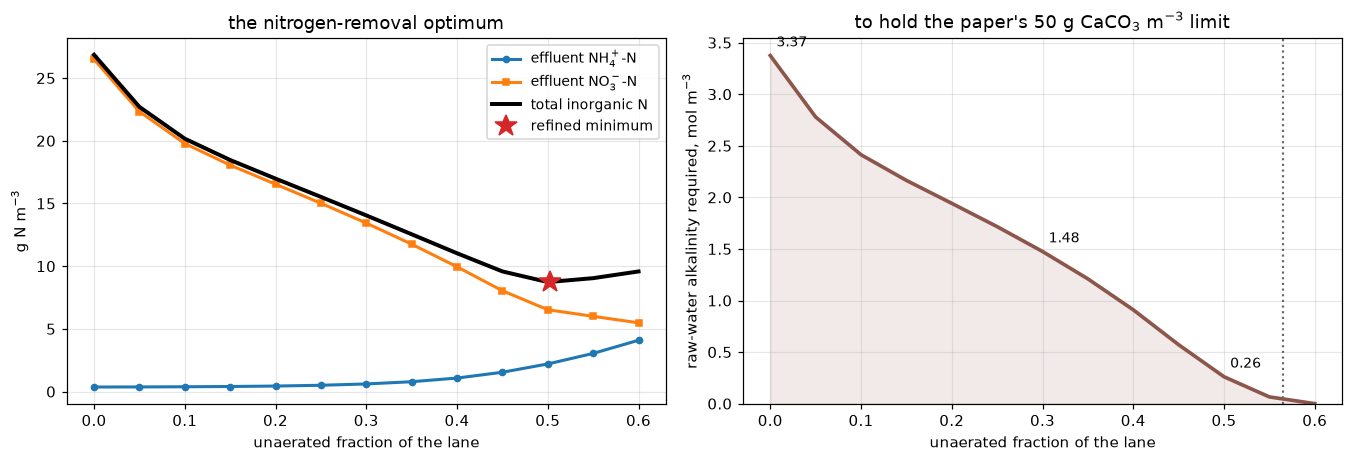

linearity check: outlet alkalinity per mol m-3 of raw-water alkalinity equals
25 g CaCO3 m-3 (the 1:1 blend) to below 1e-8 relative (here 3e-15):
alkalinity is read by no rate, so it is a passive tracer of the nitrogen conversions.

On the 100-cell lane, total inorganic nitrogen is lowest at an unaerated fraction
of 0.502 (scan of 0.00 to 0.60, refined by bounded minimisation), at 8.73 g N m-3,
against 26.85 with no anoxic zone at all: a 67 % reduction.
Beyond that, nitrification runs out of aerated volume: effluent ammonia goes from
2.20 at 0.50 to 4.10 g N m-3 at 0.60.

And the alkalinity column earns its place. The raw-water alkalinity this lane
needs in order to stay above the paper's own pH-stability threshold is
       0 % unaerated ->  3.37 mol m-3 (  169 g CaCO3 m-3)
      30 % unaerated ->  1.48 mol m-3 (   74 g CaCO3 m-3)
      50 % unaerated ->  0.26 mol m-3 (   13 g CaCO3 m-3)

The lane's own influent carries 6 mol m-3, above all three.
The requirement reaches zero at an un

In [15]:
def alk_rule(g=None):
    """Alkalinity per g N from charge continuity: (destroyed by nitrification,
    returned by denitrification), mol. nu_ALK = gamma_NH dNH + gamma_NO dNO."""
    ch = (gamma if g is None else g)["charge"]
    return -(ch["S_NH"] * -1 + ch["S_NO"] * +1), ch["S_NO"] * -1


def alk_matrix(nu=None):
    """The same two numbers read off the printed process 3 and process 2 cells."""
    nu = NU if nu is None else nu
    nit = sp.simplify(-(nu[3]["S_ALK"] + i_XB / 14) / nu[3]["S_NO"])
    den = sp.simplify((nu[2]["S_ALK"] + i_XB / 14) / -nu[2]["S_NO"])
    return nit, den


alk_nit, alk_den = alk_rule()
alk_nit_m, alk_den_m = alk_matrix()
print(f"from charge continuity alone: nitrification destroys {float(alk_nit) * CACO3:.4f} g CaCO3 per g N")
print(f"                              denitrification returns {float(alk_den) * CACO3:.4f} g CaCO3 per g N")
print(f"                              ratio {alk_nit / alk_den}, with no parameter in it\n")
print("and the check that this really is what the printed matrix says")
print("(the i_XB/14 assimilation term stripped, divided by the nitrate turned over):")
print(f"   nitrification (process 3)   {sp.sstr(alk_nit_m):>8} mol per g N")
print(f"   denitrification (process 2) {sp.sstr(alk_den_m):>8} mol per g N")
print("   (2.86 in the denitrification cell cancels exactly, so that row does not")
print("    even feel the rounding, which is why charge closed for the printed matrix)\n")

N_SWEEP = 100                                    # cells of every lane in the sweeps below
F_GRID = np.linspace(0.0, 0.60, 13)              # unaerated fractions scanned
NH, NO, ALK = IX["S_NH"], IX["S_NO"], IX["S_ALK"]


def tn_optimum(p=None):
    """Lowest total inorganic N over the unaerated fraction: a scan of the window,
    refined by bounded minimisation; an interior scan minimum is required."""
    out = np.array([lane(n=N_SWEEP, f_anox=f, p=p)["c_out"] for f in F_GRID])
    TN = out[:, NH] + out[:, NO]
    i = int(np.argmin(TN))                       # scan bracket, refined below
    if i in (0, len(F_GRID) - 1):
        raise RuntimeError(f"TN scan minimum at the window end f = {F_GRID[i]:.2f}")
    r = minimize_scalar(lambda f: tn(lane(n=N_SWEEP, f_anox=f, p=p)["c_out"]),
                        bounds=(F_GRID[i - 1], F_GRID[i + 1]), method="bounded",
                        options={"xatol": 1e-4})
    if not r.success:
        raise RuntimeError(f"TN minimisation failed: {r.message}")
    return dict(f=float(r.x), tn=float(r.fun), tn0=float(TN[0]), out=out, TN=TN)


def alk_need(c_out, blend=BLEND):
    """Raw-water alkalinity (mol m-3) that puts the outlet exactly at the paper's
    limit, using that the outlet moves CACO3 * blend per mol m-3 of raw water."""
    return WW["S_ALK"] - (c_out[ALK] * CACO3 - ALK_LIMIT) / (CACO3 * blend)


def alk_slope_dev(p=None):
    """Outlet alkalinity per mol m-3 of raw-water alkalinity, relative to CACO3 * BLEND."""
    a = [lane(n=N_SWEEP, p=p, c_feed=feed(alk=x))["c_out"][ALK] * CACO3 for x in (1.0, 0.5)]
    return abs((a[0] - a[1]) / (0.5 * WW["S_ALK"]) / (CACO3 * BLEND) - 1)


def alk_need_at(f, p=None, c_feed=None):
    """The requirement at one unaerated fraction."""
    return alk_need(lane(n=N_SWEEP, f_anox=f, p=p, c_feed=c_feed)["c_out"])


def alk_need_zero(p=None):
    """Unaerated fraction at which the alkalinity requirement reaches zero."""
    fr = find_roots(lambda f: alk_need_at(f, p), 0.0, 0.95, n_scan=20, xtol=1e-6)
    if len(fr["roots"]) != 1 or fr["failed"]:
        raise RuntimeError(f"alkalinity need: {fr['message']}")
    return fr["roots"][0]


OPT = tn_optimum()
TN_GRID = OPT["TN"]
NEED = {f: alk_need_at(f) for f in (0.0, 0.30, 0.50)}
F_ZERO = alk_need_zero()
ALK_DEV = alk_slope_dev()
need_grid = np.maximum([alk_need(o) for o in OPT["out"]], 0.0)

fig, ax = plt.subplots(1, 2, figsize=(12.4, 4.3))
ax[0].plot(F_GRID, OPT["out"][:, NH], "o-", lw=2, ms=4, label="effluent NH$_4^+$-N")
ax[0].plot(F_GRID, OPT["out"][:, NO], "s-", lw=2, ms=4, label="effluent NO$_3^-$-N")
ax[0].plot(F_GRID, TN_GRID, "-", lw=2.6, color="k", label="total inorganic N")
ax[0].plot(OPT["f"], OPT["tn"], "*", ms=15, color="tab:red", zorder=5, label="refined minimum")
ax[0].set(xlabel="unaerated fraction of the lane", ylabel="g N m$^{-3}$",
          title="the nitrogen-removal optimum")
ax[0].legend(fontsize=9)

ax[1].plot(F_GRID, need_grid, "-", lw=2.4, color="tab:brown")
ax[1].fill_between(F_GRID, 0, need_grid, color="tab:brown", alpha=0.12)
ax[1].axvline(F_ZERO, color="0.4", ls=":", lw=1.4)
ax[1].set(xlabel="unaerated fraction of the lane",
          ylabel="raw-water alkalinity required, mol m$^{-3}$",
          title="to hold the paper's 50 g CaCO$_3$ m$^{-3}$ limit", ylim=(0, None))
for f, v in NEED.items():
    ax[1].annotate(f"{v:.2f}", (f, v), textcoords="offset points", xytext=(4, 6), fontsize=9)
fig.tight_layout(); plt.show()

print(f"linearity check: outlet alkalinity per mol m-3 of raw-water alkalinity equals")
print(f"{CACO3 * BLEND:.0f} g CaCO3 m-3 (the 1:1 blend) to below 1e-8 relative (here {ALK_DEV:.0e}):")
print("alkalinity is read by no rate, so it is a passive tracer of the nitrogen conversions.\n")
print(f"On the {N_SWEEP}-cell lane, total inorganic nitrogen is lowest at an unaerated fraction")
print(f"of {OPT['f']:.3f} (scan of {F_GRID[0]:.2f} to {F_GRID[-1]:.2f}, refined by bounded "
      f"minimisation), at {OPT['tn']:.2f} g N m-3,")
print(f"against {OPT['tn0']:.2f} with no anoxic zone at all: a "
      f"{100 * (1 - OPT['tn'] / OPT['tn0']):.0f} % reduction.")
print(f"Beyond that, nitrification runs out of aerated volume: effluent ammonia goes from")
print(f"{lane(n=N_SWEEP, f_anox=0.50)['c_out'][NH]:.2f} at 0.50 to "
      f"{OPT['out'][-1, NH]:.2f} g N m-3 at {F_GRID[-1]:.2f}.\n")
print("And the alkalinity column earns its place. The raw-water alkalinity this lane")
print("needs in order to stay above the paper's own pH-stability threshold is")
for f, v in NEED.items():
    print(f"   {100 * f:5.0f} % unaerated ->{v:6.2f} mol m-3 ({CACO3 * v:5.0f} g CaCO3 m-3)")
print(f"\nThe lane's own influent carries {WW['S_ALK']:.0f} mol m-3, above all three.")
print(f"The requirement reaches zero at an unaerated fraction of {F_ZERO:.3f}")
print("(root-found over 0 to 0.95, one root), but only because nitrification is by then")
print("incomplete: the alkalinity is spared because the ammonia is not removed, which")
print("is not a design anyone wants.")

In [16]:
def ka_study(values=None):
    """Outlet at the two ammonification coefficients Table 4 prints."""
    values = (P["k_a"], K_A_ALT) if values is None else values
    outs = []
    for ka in values:
        p = dict(P)
        p["k_a"] = ka
        outs.append(lane(n=N_SWEEP, p=p)["c_out"])
    sol_n = [tn(o) + o[IX["S_ND"]] for o in outs]   # soluble N, organic plus inorganic
    return dict(outs=outs, snd=float(outs[1][IX["S_ND"]] / outs[0][IX["S_ND"]] - 1),
                tn=float(tn(outs[1]) / tn(outs[0]) - 1), soln=float(sol_n[1] / sol_n[0] - 1))


KA = ka_study()
print("The ammonification coefficient, at both values Table 4 prints\n")
for label, s in ((f"k_a = {P['k_a']:.3f} (the row carrying the model's symbol)", KA["outs"][0]),
                 (f"k_A = {K_A_ALT:.3f} (the undefined twentieth row)", KA["outs"][1])):
    print(f"   {label:<50} S_ND {s[IX['S_ND']]:6.3f}  S_NH {s[NH]:6.3f}"
          f"  S_NO {s[NO]:7.3f}  alk {s[ALK] * CACO3:7.2f}")
print(f"\n   The larger value moves soluble organic nitrogen by {100 * KA['snd']:+.0f} % and")
print(f"   effluent inorganic nitrogen by {100 * KA['tn']:+.0f} %, while soluble nitrogen in total")
print(f"   moves by {100 * KA['soln']:+.1f} %: faster ammonification turns the organic pool into")
print("   ammonium inside the lane, and the aerated zone nitrifies it, so the nitrogen leaves")
print("   as nitrate instead. The choice matters for effluent nitrate; it does not touch")
print("   continuity at all: no kinetic parameter appears in any of the checks above.")

The ammonification coefficient, at both values Table 4 prints

   k_a = 0.016 (the row carrying the model's symbol)  S_ND  3.823  S_NH  0.611  S_NO  13.437  alk  163.12
   k_A = 0.080 (the undefined twentieth row)          S_ND  0.805  S_NH  1.028  S_NO  15.949  alk  155.64

   The larger value moves soluble organic nitrogen by -79 % and
   effluent inorganic nitrogen by +21 %, while soluble nitrogen in total
   moves by -0.5 %: faster ammonification turns the organic pool into
   ammonium inside the lane, and the aerated zone nitrifies it, so the nitrogen leaves
   as nitrate instead. The choice matters for effluent nitrate; it does not touch
   continuity at all: no kinetic parameter appears in any of the checks above.


**What this page does not establish.** No comparison with a
measurement, anywhere, and that is a property of the source: the abbreviated
report contains no worked example, no calibrated plant and no dataset. Its one
figure with data in it is borrowed from Ekama et al. (1986) to show a
*measurement procedure*. So `J4.8` validates a **transcription and its internal
consistency**, not a prediction, and it says so rather than manufacturing a
comparison.

The reactor inherits every one of the paper's own restrictions (constant
temperature, constant near-neutral pH, no inorganic suspended solids) and adds
some of its own: plug flow with no axial dispersion, a settler treated as a
perfect separation point, mixed-liquor solids imposed at the inlet rather than
set by a sludge age, and an operating point chosen by us. The trade-off curves
above are therefore a demonstration of what the matrix implies on one grid, not
a design calculation for any real plant.

And the continuity check has a boundary worth naming. It tests the matrix against
the component *definitions*. It cannot tell you whether $\rho_7$'s hydrolysis
saturation is the right functional form, where in its printed range $\eta_g$
lies, or whether decay really is independent of electron acceptor. Continuity
constrains stoichiometry; it says nothing about kinetics.

## Reuse

**The continuity test is the reusable part, and it is not specific to ASM1.**
Any Petersen-matrix model (ASM2, ASM3, ADM1, a mixed-culture bioprocess written
in the same format) carries composition vectors that must annihilate every row.
`model.continuity(nu, gamma[law])` needs only the composition vector and the
matrix. Run it *before* you run the model: it catches sign errors, dropped terms
and transcription slips that a simulation will happily absorb into a slightly
wrong oxygen demand.

**Solving continuity for a missing cell is how you should fill one in.** Check 2
above recovers printed coefficients from the balances (`model.recover_cell`). The
same call fills a genuinely unknown coefficient, which is the standard way to
extend one of these matrices with a new process: write the cells the process
definition fixes, then let the three balances supply the electron acceptor, the
ammonium and the alkalinity.

**Add S_N2 whenever nitrate is reduced.** ASM1's nitrogen balance cannot close
without it, and the missing $(1-Y_H)/(2.86\,Y_H)$ (printed in the results over
Table 4's yield range) is easy to mistake for a bug in your own code.

**The pymrm piece is a reaction network on a 1-D convective grid**
(`model.Lane`): `construct_convflux_upwind` + `construct_div` for transport,
`NumJac((n, n_c))` + `newton` for the steady state. `NumJac` with no
`axes_diagonals` is right here because the source is pointwise; add
`axes_diagonals=[0]` the moment a source term reads a neighbouring cell (a
biofilm flux, a settling velocity). A recycle, or any inlet that depends on the
state, goes into the same Newton system through `shapes_d` and a constant
coupling matrix, as in `Lane.__init__`. Swapping ASM1 for any other network
means replacing `rates` and the matrix, and nothing else.

**Two traps met while building this**, both measured above. The recycle as a
fixed-point iteration on the inlet value contracts at about $R/(1+R)$ per
iterate, the slow, passive components setting the pace (check 6); placing the
recycle inside the Newton system removes the iteration. And take the boundary
fluxes from the convection operator (its exit face) rather than from a cell
value picked by hand: reading the outlet one cell upstream breaks the COD
balance, which has a source along the lane; nitrogen and charge do not notice it
(break table).

**Related pages.** `J4.7` (enzyme kinetics in a pellet), `I1.2` (a reaction
network with strong switching behaviour), [`C2.1`](../C2.1-xu-froment-smr/)
(a multi-reaction network validated against measurements rather than against
itself).

**Cite the source, not this page:** Henze, M., Grady, C. P. L. Jr, Gujer, W.,
Marais, G. v. R. and Matsuo, T., *A general model for single-sludge wastewater
treatment systems*, Water Research **21**(5), 505-515 (1987),
doi:10.1016/0043-1354(87)90058-3. The full report is IAWPRC Scientific and
Technical Report No. 1.

### Claims and the break table

Every number the page states is registered with how it is checked
(`docs/claims-design.md`). The symbolic results are exact; the reactor
balances are round-off of a conservative discretisation, so they are bounds
with basis identity, 1e-8 g m⁻³ d⁻¹ being far below both the oxygen demand and
the COD leak. Each non-structural claim then has a row of the break table: a
defect injected through an argument of the same functions, which must fail
that claim's own check.

In [17]:
claims.exact("charge_residuals_all_zero", all(res["charge"][j] == 0 for j in NU))
claims.exact("nitrogen_residuals_all_zero", all(res["N"][j] == 0 for j in NU))
claims.exact("cod_closed_count", n_cod_closed)
claims.value("cod_residual_p2", float(res["COD"][2].subs(STOICH)))
claims.value("cod_residual_p3", float(res["COD"][3].subs(STOICH)))
claims.exact("cod_residual_p2_symbolic", sp.sstr(res["COD"][2]))
claims.exact("cod_residual_p3_symbolic", sp.sstr(res["COD"][3]))
claims.exact("cod_residuals_zero_with_exact_factors", all(res_exact["COD"][j] == 0 for j in NU))
claims.exact("coefficients_recovered_identically", n_exact)
claims.exact("coefficients_recovered_up_to_rounding", n_rounding)
claims.exact("eq3_cross_check", delta_eq3 == 0)
claims.value("n_loss_no_n2_min", loss_lo, unit="g N per g COD")
claims.value("n_loss_no_n2_max", loss_hi, unit="g N per g COD")
claims.value("lane_otr", otr150, unit="g O2 m-3 d-1")
claims.value("xbh_change_one_pass", xbh_change)
claims.bound("reactor_charge_balance", study_max(RS, "charge"), max=1e-8, basis="identity",
             unit="g m-3 d-1", note="identity of a conservative scheme at a converged solve: charge closes to round-off, max over n = 75, 150, 300")
claims.bound("reactor_nitrogen_balance", study_max(RS, "N"), max=1e-8, basis="identity",
             unit="g m-3 d-1", note="identity of a conservative scheme at a converged solve: nitrogen closes to round-off, max over n = 75, 150, 300")
claims.value("reactor_cod_leak", leak150, unit="g m-3 d-1")
claims.value("reactor_cod_leak_grid_change", leak_grid_change(RS),
             note="relative change of the COD leak from n = 75 to n = 300")
claims.bound("reactor_cod_leak_vs_prediction", study_max(RS, "pred"), max=1e-8, basis="identity",
             note="identity of a conservative scheme at a converged solve: the leak is the matrix's two residuals times the rates, to round-off, max over grids")
claims.bound("reactor_cod_leak_exact_factors", study_max(RS_EXACT, "COD"), max=1e-8,
             basis="identity", unit="g m-3 d-1",
             note="with 20/7 and 32/7 COD closes; exactly 0 on some BLAS kernels")
claims.value("reactor_cod_leak_fraction_of_otr", leak150 / otr150)
claims.bound("zg_last_cell_balance", ZG["bal"], max=1e-8, basis="identity", unit="g m-3 d-1",
             note="zero-gradient exit, outflow read from the last cell: nitrogen and charge, n = 150")
claims.value("zg_last_cell_cod_shift", ZG["shift"], unit="g m-3 d-1")
claims.bound("lane_order_min", OS["min"], min=0.9, basis="theory",
             note="first-order upwind; outlet S_NH and S_ND, successive differences, n = 100 to 1600")
claims.bound("lane_order_max", OS["max"], max=1.1, basis="theory",
             note="first-order upwind; outlet S_NH and S_ND, successive differences, n = 100 to 1600")
claims.bound("lane_order_preasymptotic_max", OS["slow_max"], max=0.8, basis="chosen",
             note="the other outlet values are not in the asymptotic range on n = 100 to 1600")
claims.value("tn_grid_change", OS["tn_change"])
claims.bound("lane_order_roundoff_margin", OS["margin"], min=1e3, basis="tolerance",
             note="finest successive difference over max(newton tol, eps |q|)")
claims.value("picard_iterations", PC["outer"])
claims.value("picard_contraction", PC["contraction"])
claims.bound("recycle_routes_gap", PC["gap"], max=1e-8, basis="tolerance", unit="g m-3",
             note="fixed-point route stopped at an inlet step of 1e-9")
claims.exact("alk_nit_den_ratio", float(alk_nit / alk_den))
claims.exact("alk_matrix_matches_rule", bool(alk_nit_m == alk_nit and alk_den_m == alk_den))
claims.bound("alk_linearity_dev", ALK_DEV, max=1e-8, basis="identity",
             note="alkalinity is read by no rate: a passive tracer")
claims.value("tn_optimum_fraction", OPT["f"])
claims.value("tn_at_optimum", OPT["tn"], unit="g N m-3")
claims.value("tn_no_anoxic", OPT["tn0"], unit="g N m-3")
claims.value("tn_reduction_at_optimum", 1 - OPT["tn"] / OPT["tn0"])
claims.value("alk_need_f0", NEED[0.0], unit="mol m-3")
claims.value("alk_need_f30", NEED[0.30], unit="mol m-3")
claims.value("alk_need_f50", NEED[0.50], unit="mol m-3")
claims.value("alk_need_zero_fraction", F_ZERO)
claims.value("ka_snd_rel_change", KA["snd"])
claims.value("ka_tn_rel_change", KA["tn"])
claims.value("ka_soluble_n_rel_change", KA["soln"])

In [18]:
G_NH7 = asm.composition_vectors(COMPS, charge_nh=sp.Rational(1, 7))
G_NO457 = asm.composition_vectors(COMPS, cod_no=-sp.Rational(457, 100))
NU_NO_N2 = asm.petersen_matrix(stoi, C13, add_n2=False)
NU_P7 = {j: dict(v) for j, v in NU.items()}
NU_P7[7]["S_S"] = 1 - f_P
P_ETA0 = dict(P, eta_g=0.0)
P_BH2 = dict(P, b_H=2.0 * P["b_H"])
P_KALK = dict(P, K_ALK=0.5)


def res_g(g, law, j=None):
    """Continuity under defective composition vectors."""
    r = continuity_all(g=g)[law]
    return r if j is None else r[j]


def reactor_g(g, key, **kw):
    return study_max(reactor_study(g_num=numeric_gamma(g), **kw), key)


def opt_or_nan(key, p):
    try:
        o = tn_optimum(p=p)
    except RuntimeError as exc:
        print(f"   tn_optimum raised: {exc}; records nan")
        return np.nan
    return {"f": o["f"], "tn": o["tn"], "tn0": o["tn0"], "red": 1 - o["tn"] / o["tn0"]}[key]


ROWS = [
    ("NH4+ charge taken as +1/7 per g N", {
        "charge_residuals_all_zero": lambda: all(v == 0 for v in res_g(G_NH7, "charge").values()),
        "reactor_charge_balance": lambda: reactor_g(G_NH7, "charge"),
        "alk_nit_den_ratio": lambda: float(alk_rule(G_NH7)[0] / alk_rule(G_NH7)[1]),
        "alk_matrix_matches_rule": lambda: bool(alk_matrix() == alk_rule(G_NH7))}),
    ("S_N2 cell left blank, as printed", {
        "nitrogen_residuals_all_zero": lambda: all(
            v == 0 for v in asm.continuity(NU_NO_N2, gamma["N"]).values()),
        "reactor_nitrogen_balance": lambda: study_max(
            reactor_study(nu_m=asm.numeric_matrix(NU_NO_N2, STOICH)), "N"),
        "zg_last_cell_balance": lambda: zg_study(nu_m=asm.numeric_matrix(NU_NO_N2, STOICH))["bal"]}),
    ("nitrate COD taken as -4.57 per g N, not -32/7", {
        "cod_closed_count": lambda: sum(v == 0 for v in res_g(G_NO457, "COD").values()),
        "cod_residual_p2": lambda: float(res_g(G_NO457, "COD", 2).subs(STOICH)),
        "cod_residual_p3": lambda: float(res_g(G_NO457, "COD", 3).subs(STOICH)),
        "cod_residual_p2_symbolic": lambda: sp.sstr(res_g(G_NO457, "COD", 2)),
        "cod_residual_p3_symbolic": lambda: sp.sstr(res_g(G_NO457, "COD", 3)),
        "cod_residuals_zero_with_exact_factors": lambda: all(
            v == 0 for v in asm.continuity(NU_EXACT, G_NO457["COD"]).values()),
        "coefficients_recovered_identically": lambda: recovery(g=G_NO457)[0],
        "coefficients_recovered_up_to_rounding": lambda: recovery(g=G_NO457)[1],
        "reactor_cod_leak": lambda: abs(reactor_study(
            g_num=numeric_gamma(G_NO457), grids=(150,))[150]["b"]["COD"]),
        "reactor_cod_leak_fraction_of_otr": lambda: (lambda o: abs(o["b"]["COD"]) / o["otr"])(
            reactor_study(g_num=numeric_gamma(G_NO457), grids=(150,))[150])}),
    ("process-7 S_S cell read as 1 - f_P", {
        "eq3_cross_check": lambda: eq3_delta(NU_P7) == 0}),
    ("outlet flux read one cell upstream (c[-2])", {
        "reactor_cod_leak_vs_prediction": lambda: study_max(
            reactor_study(flux_read="upstream"), "pred")}),
    ("exact-factor lane run on the printed decimals", {
        "reactor_cod_leak_exact_factors": lambda: study_max(reactor_study(nu_m=NU_M), "COD")}),
    ("Y_H range read from the Y_A row of Table 4", {
        "n_loss_no_n2_min": lambda: n_loss_range("Y_A")[0],
        "n_loss_no_n2_max": lambda: n_loss_range("Y_A")[1]}),
    ("heterotroph decay rate b_H doubled", {
        "lane_otr": lambda: lane(p=P_BH2)["otr"],
        "xbh_change_one_pass": lambda: (lambda s: s["c_out"][IX["X_BH"]] / s["c_in"][IX["X_BH"]] - 1)(
            lane(p=P_BH2)),
        "zg_last_cell_cod_shift": lambda: zg_study(p=P_BH2)["shift"]}),
    ("oxygen transfer per cell (kLa times the cell width)", {
        "reactor_cod_leak_grid_change": lambda: leak_grid_change(
            reactor_study(kla_per_cell=True, grids=(GRIDS[0], GRIDS[-1]))),
        "lane_order_min": lambda: order_study(kla_per_cell=True)["min"],
        "lane_order_max": lambda: order_study(kla_per_cell=True)["max"],
        "lane_order_preasymptotic_max": lambda: order_study(kla_per_cell=True)["slow_max"],
        "tn_grid_change": lambda: order_study(kla_per_cell=True)["tn_change"]}),
    ("Newton step tolerance 1e-1 on the grid ladder", {
        "lane_order_roundoff_margin": lambda: order_study(tol=1e-1)["margin"]}),
    ("fixed-point recycle stopped at an inlet step of 1e-4", {
        "picard_iterations": lambda: picard_study(tol=1e-4)["outer"],
        "recycle_routes_gap": lambda: picard_study(tol=1e-4)["gap"]}),
    ("recycle ratio 4 in the fixed-point route", {
        "picard_contraction": lambda: picard_study(R=4.0)["contraction"]}),
    ("anoxic growth switched off (eta_g = 0)", {
        "tn_optimum_fraction": lambda: opt_or_nan("f", P_ETA0),
        "tn_at_optimum": lambda: opt_or_nan("tn", P_ETA0),
        "tn_reduction_at_optimum": lambda: opt_or_nan("red", P_ETA0)}),
    ("influent ammonia doubled", {
        "tn_no_anoxic": lambda: tn(lane(n=N_SWEEP, f_anox=0.0, c_feed=feed(nh=2.0))["c_out"]),
        "alk_need_f0": lambda: alk_need_at(0.0, c_feed=feed(nh=2.0))}),
    ("nitrification switched by alkalinity, K_ALK = 0.5 mol m-3 (not in ASM1)", {
        "alk_linearity_dev": lambda: alk_slope_dev(P_KALK),
        "alk_need_f30": lambda: alk_need_at(0.30, P_KALK),
        "alk_need_f50": lambda: alk_need_at(0.50, P_KALK),
        "alk_need_zero_fraction": lambda: alk_need_zero(P_KALK)}),
    ("k_A row read as k_a (one ammonification value)", {
        "ka_snd_rel_change": lambda: ka_study((P["k_a"], P["k_a"]))["snd"],
        "ka_tn_rel_change": lambda: ka_study((P["k_a"], P["k_a"]))["tn"],
        "ka_soluble_n_rel_change": lambda: ka_study((P["k_a"], P["k_a"]))["soln"]}),
]

claims.define_rows([r[0] for r in ROWS])
BREAK = []
for row, studies in ROWS:
    for name, fn in studies.items():
        try:
            out = fn()
        except Exception as exc:                 # noqa: BLE001 - a failed study is a result
            print(f"  {row}: {name} raised {type(exc).__name__}: {str(exc)[:70]}; records nan")
            out = np.nan
        caught_ = claims.breaks(row, name, out)
        base_ = claims.metrics[name]["value"]
        if claims.metrics[name]["kind"] == "bound":   # round-off digits differ between machines
            base_, out = f"(here {base_:.1e})", f"(here {float(out):.1e})"
        BREAK.append((row, name, base_, out, caught_))

bt = pd.DataFrame(BREAK, columns=["injected defect", "metric", "baseline", "with defect", "caught"])
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.max_rows", 300)
print(bt.to_string(index=False, float_format=lambda v: f"{v:.6g}"))
idle = [r for r in bt["injected defect"].unique()
        if not bt[(bt["injected defect"] == r) & bt.caught].shape[0]]
print(f"\n{len(ROWS)} rows defined, {bt['injected defect'].nunique()} in the table; "
      f"rows that fail no claim: {idle or 'none'}")
missing = [k for k in claims.metrics if not bt[(bt.metric == k) & bt.caught].shape[0]]
print(f"claims no row fails: {missing or 'none'}")

   tn_optimum raised: TN scan minimum at the window end f = 0.60; records nan


   tn_optimum raised: TN scan minimum at the window end f = 0.60; records nan


   tn_optimum raised: TN scan minimum at the window end f = 0.60; records nan


                                                        injected defect                                metric             baseline            with defect  caught
                                      NH4+ charge taken as +1/7 per g N             charge_residuals_all_zero                 True                  False    True
                                      NH4+ charge taken as +1/7 per g N                reactor_charge_balance       (here 4.3e-14)         (here 3.2e+00)    True
                                      NH4+ charge taken as +1/7 per g N                     alk_nit_den_ratio                    2                      3    True
                                      NH4+ charge taken as +1/7 per g N               alk_matrix_matches_rule                 True                  False    True
                                       S_N2 cell left blank, as printed           nitrogen_residuals_all_zero                 True                  False    True
                            

### Claims and the prose

Every number the README states is checked below against the claim it quotes,
so a number in the text cannot drift from the computation and a cut in its
precision shows in CI (agreement.json "quoted"). Round-off-level results are
quoted as bounds.

In [19]:
SAYS = {
    "n_loss_no_n2_min": ["0.16"],
    "n_loss_no_n2_max": ["0.41"],
    "cod_closed_count": ["6"],
    "coefficients_recovered_identically": ["8"],
    "coefficients_recovered_up_to_rounding": ["2"],
    "picard_iterations": ["57"],
    "picard_contraction": ["0.65"],
    "recycle_routes_gap": ["below 1e-8"],
    "reactor_nitrogen_balance": ["below 1e-8"],
    "reactor_charge_balance": ["below 1e-8"],
    "lane_otr": ["652"],
    "reactor_cod_leak": ["0.2071"],
    "reactor_cod_leak_grid_change": ["0.19 %"],
    "reactor_cod_leak_vs_prediction": ["below 1e-8"],
    "reactor_cod_leak_exact_factors": ["below 1e-8"],
    "lane_order_min": ["at least 0.9"],
    "lane_order_max": ["at most 1.1"],
    "lane_order_preasymptotic_max": ["below 0.8"],
    "tn_grid_change": ["0.6 %"],
    "alk_nit_den_ratio": ["2"],
    "tn_optimum_fraction": ["0.50"],
    "tn_at_optimum": ["8.73"],
    "tn_no_anoxic": ["26.85"],
    "tn_reduction_at_optimum": ["67 %"],
    "alk_need_f0": ["3.37"],
    "alk_need_f30": ["1.48"],
    "alk_need_f50": ["0.26"],
    "alk_need_zero_fraction": ["0.566"],
    "ka_snd_rel_change": ["-79 %"],
    "ka_tn_rel_change": ["21 %"],
    "ka_soluble_n_rel_change": ["-0.5 %"],
    "reactor_cod_leak_fraction_of_otr": ["0.032 %"],
    "zg_last_cell_balance": ["below 1e-8"],
    "zg_last_cell_cod_shift": ["0.51"],
}
for _k, _lits in SAYS.items():
    for _lit in _lits:
        claims.says(_lit, _k)
print(f"prose literals: {sum(len(v) for v in SAYS.values())} checked against their claims with claims.says")

prose literals: 34 checked against their claims with claims.says


In [20]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for J4.8:
  charge_residuals_all_zero             = True             exact  exact
  nitrogen_residuals_all_zero           = True             exact  exact
  cod_closed_count                      = 6                exact  exact
  cod_residual_p2                       = -0.00077422      value  rtol 0.05
  cod_residual_p3                       = -0.010204        value  rtol 0.05
  cod_residual_p2_symbolic              = '(Y_H - 1)/(1001*Y_H)' exact  exact
  cod_residual_p3_symbolic              = '-1/(700*Y_A)'   exact  exact
  cod_residuals_zero_with_exact_factors = True             exact  exact
  coefficients_recovered_identically    = 8                exact  exact
  coefficients_recovered_up_to_rounding = 2                exact  exact
  eq3_cross_check                       = True             exact  exact
  n_loss_no_n2_min                      = 0.15709          value  rtol 0.05
  n_loss_no_n2_max                      = 0.41046          value  rtol 0.05
  lane_otr               